In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\sanush\vol-spike-alert\data\nifty50_raw.csv",skiprows=[1,2])
#This dataset was downloaded from yfinance library and row 1 had tracker symbol and row 2 had null values so those rows were skipped while reading

In [3]:
df.head()

,Price,Close,High,Low,Open,Volume
0,2007-09-17,4494.649902,4549.049805,4482.850098,4518.450195,0
1,2007-09-18,4546.200195,4551.799805,4481.549805,4494.100098,0
2,2007-09-19,4732.350098,4739.000000,4550.250000,4550.250000,0
3,2007-09-20,4747.549805,4760.850098,4721.149902,4734.850098,0
4,2007-09-21,4837.549805,4855.700195,4733.700195,4752.950195,0


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4691 entries, 0 to 4690
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Price   4691 non-null   str    
 1   Close   4691 non-null   float64
 2   High    4691 non-null   float64
 3   Low     4691 non-null   float64
 4   Open    4691 non-null   float64
 5   Volume  4691 non-null   int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 265.8 KB


In [5]:
df.shape

(4691, 6)

In [6]:
df.dtypes

Price         str
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

In [7]:
df.describe()

,Close,High,Low,Open,Volume
count,4691.000000,4691.000000,4691.000000,4691.000000,4.691000e+03
mean,11486.952126,11553.073671,11418.083315,11493.289151,2.188763e+05
std,6755.523161,6778.406764,6731.588168,6757.797114,2.055859e+05
min,2524.199951,2585.300049,2252.750000,2553.600098,0.000000e+00
25%,5744.600098,5796.925049,5693.800049,5749.774902,0.000000e+00
50%,9103.500000,9149.599609,9043.950195,9104.000000,1.972000e+05
75%,17066.174805,17179.474609,16941.474609,17077.849609,3.071000e+05
max,26328.550781,26373.199219,26210.050781,26333.699219,1.811000e+06


In [8]:
df.isna().sum()

Price     0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

In [9]:
df.tail()

,Price,Close,High,Low,Open,Volume
4686,2026-10-26,22753.199219,22753.199219,22387.349609,22524.400391,310200
4687,2026-10-27,22749.750000,22829.750000,22636.849609,22708.800781,400900
4688,2026-10-28,22698.849609,22778.050781,22497.699219,22678.000000,295000
4689,2026-10-29,22936.750000,22961.949219,22656.750000,22690.650391,344000
4690,2026-10-30,23053.099609,23118.099609,22905.099609,22964.500000,328600


In [10]:
df=df.rename(columns={"Price":"Dates"})
#The dates column was named "Price" so it was changed into "Dates"

In [11]:
df.head()

,Dates,Close,High,Low,Open,Volume
0,2007-09-17,4494.649902,4549.049805,4482.850098,4518.450195,0
1,2007-09-18,4546.200195,4551.799805,4481.549805,4494.100098,0
2,2007-09-19,4732.350098,4739.000000,4550.250000,4550.250000,0
3,2007-09-20,4747.549805,4760.850098,4721.149902,4734.850098,0
4,2007-09-21,4837.549805,4855.700195,4733.700195,4752.950195,0


In [12]:
df["Dates"]=pd.to_datetime(df["Dates"])
#the data type of "Dates" was Str so it was changed into datetime

In [13]:
df.head()

,Dates,Close,High,Low,Open,Volume
0,2007-09-17,4494.649902,4549.049805,4482.850098,4518.450195,0
1,2007-09-18,4546.200195,4551.799805,4481.549805,4494.100098,0
2,2007-09-19,4732.350098,4739.000000,4550.250000,4550.250000,0
3,2007-09-20,4747.549805,4760.850098,4721.149902,4734.850098,0
4,2007-09-21,4837.549805,4855.700195,4733.700195,4752.950195,0


In [14]:
df.dtypes

Dates     datetime64[us]
Close            float64
High             float64
Low              float64
Open             float64
Volume             int64
dtype: object

In [15]:
df.isna().sum()

Dates     0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

In [16]:
df["Years"]=df["Dates"].dt.year
#There was no source to fetch the volume data so 1333 values were given 0. so in order to filter those years we added a seperate Year column

In [17]:
df.head()

,Dates,Close,High,Low,Open,Volume,Years
0,2007-09-17,4494.649902,4549.049805,4482.850098,4518.450195,0,2007
1,2007-09-18,4546.200195,4551.799805,4481.549805,4494.100098,0,2007
2,2007-09-19,4732.350098,4739.000000,4550.250000,4550.250000,0,2007
3,2007-09-20,4747.549805,4760.850098,4721.149902,4734.850098,0,2007
4,2007-09-21,4837.549805,4855.700195,4733.700195,4752.950195,0,2007


In [18]:
df.tail()

,Dates,Close,High,Low,Open,Volume,Years
4686,2026-10-26,22753.199219,22753.199219,22387.349609,22524.400391,310200,2026
4687,2026-10-27,22749.750000,22829.750000,22636.849609,22708.800781,400900,2026
4688,2026-10-28,22698.849609,22778.050781,22497.699219,22678.000000,295000,2026
4689,2026-10-29,22936.750000,22961.949219,22656.750000,22690.650391,344000,2026
4690,2026-10-30,23053.099609,23118.099609,22905.099609,22964.500000,328600,2026


In [19]:
#volumn column is grouped with respect to unique Years 
zero_volume=df.groupby("Years")["Volume"].apply(
    lambda x : (x==0).mean()
)
zero_volume
#x==0 creates boolean series for each year group
#.mean() here we get the years where volume is 0 and the years where we have volumes


Years
2007    1.000000
2008    1.000000
2009    1.000000
2010    1.000000
2011    1.000000
2012    1.000000
2013    0.052632
2014    0.000000
2015    0.000000
2016    0.000000
2017    0.004032
2018    0.053061
2019    0.000000
2020    0.008000
2021    0.016129
2022    0.004032
2023    0.008163
2024    0.020325
2025    0.000000
2026    0.000000
Name: Volume, dtype: float64

#### zeros cover 100%of 2007-2012 and drop about 5 % in 2013, so real volume starts in early 2013. There are also scattered zeros later. Even the real volume years are not fully clean , so we need to stop treating it as a feature source

In [71]:
#we needed a return column to know the fractional daily percentage returns between consecutive days close price.
df["Return"]=df["Close"].pct_change()

In [72]:
df["vol_20"]=df["Return"].rolling(window=20).std()
#creating a column for how much the market bounced over the last 20 trading day


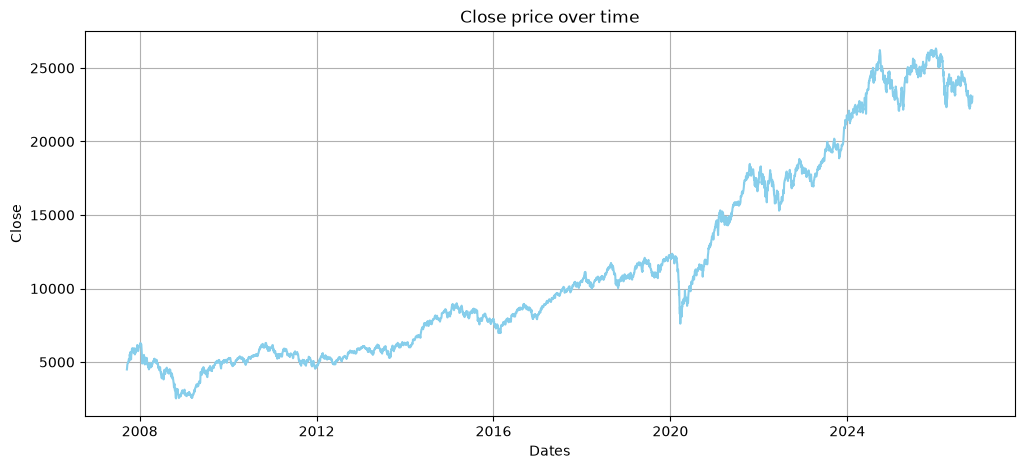

In [73]:
#chart showing the change in closing price over time
plt.figure(figsize=(12,5))
plt.plot(df["Dates"],df["Close"],color="skyblue")
plt.title("Close price over time")
plt.xlabel("Dates")
plt.ylabel("Close")
plt.grid(True)
plt.show()

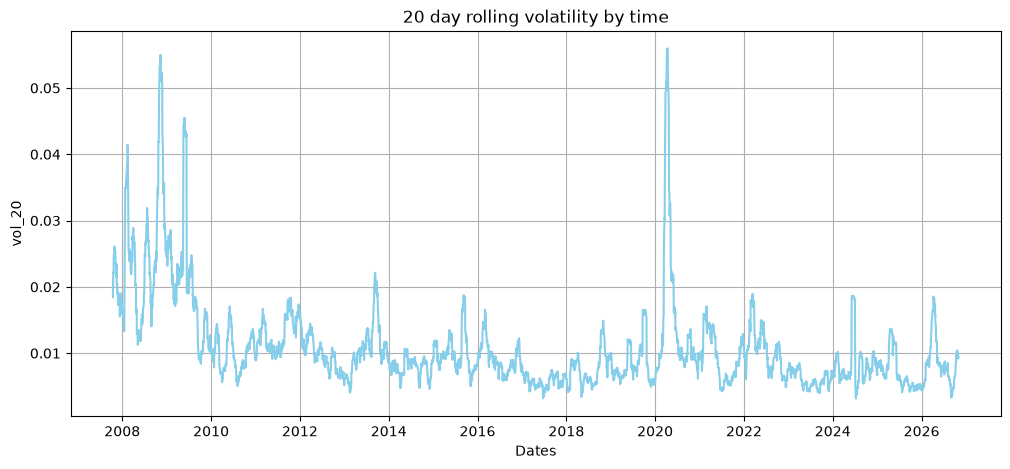

In [74]:
#chart showing vol_20 over time
plt.figure(figsize=(12,5))
plt.plot(df["Dates"],df["vol_20"],color="skyblue")
plt.title("20 day rolling volatility by time")
plt.xlabel("Dates")
plt.ylabel("vol_20")
plt.grid(True)
plt.show()

### Checking if the spikes match real events

In [75]:
df["Return"].describe()

count    4690.000000
mean        0.000432
std         0.012908
min        -0.129805
25%        -0.005227
50%         0.000552
75%         0.006501
max         0.177441
Name: Return, dtype: float64

In [76]:
df["Return"].idxmax()

402

In [77]:
df["Return"].idxmin()

3057

In [78]:
df.loc[402]

Dates     2009-05-18 00:00:00
Close             4323.149902
High              4384.299805
Low               3673.149902
Open              3673.149902
Volume                      0
Years                    2009
Return               0.177441
vol_20               0.044066
Target                      0
Name: 402, dtype: object

In [79]:
df.loc[3057] #crash caused during covid-19

Dates     2020-03-23 00:00:00
Close                 7610.25
High                  8159.25
Low               7583.600098
Open              7945.700195
Volume                 653500
Years                    2020
Return              -0.129805
vol_20               0.042488
Target                      1
Name: 3057, dtype: object

### Our main goals will be two things
#### 1. Fixed threshold --> Spike if tomorrow's absolute return exceeds the given rate(2%)
#### 2. Relative to recent volatility --> Spike if tomorrow's absolute return exceeds k * (today's vol_20)

In [80]:
Fixed_Threshold=0.02 #this value filters out almost all the small daily price movements
vol_multiplier=3 # statistically anything over 3 SD is considered a rare event
# tomorrow's absolute returns
Tomorrow_abs_return=df["Return"].abs().shift(-1) #calculates the absolute magnitude of tomorrow's return for each row
con_fixed=Tomorrow_abs_return>Fixed_Threshold
con_relative=Tomorrow_abs_return>(vol_multiplier*df["vol_20"])
df["Target"]=(con_fixed | con_relative).astype(int)

#### A total of 19 rows lacks a 20 day volatility window

In [81]:
# dropping rows where vol_20 or target columns have null values and copying it to df_model to avoid future errors
df_model=df.dropna(subset=["vol_20","Target"]).copy()

In [82]:
df_model

,Dates,Close,High,Low,Open,Volume,Years,Return,vol_20,Target
20,2007-10-16,5668.049805,5708.350098,5578.450195,5670.649902,0,2007,-0.000414,0.018438,0
21,2007-10-17,5559.299805,5658.899902,5107.299805,5658.899902,0,2007,-0.019186,0.019700,1
22,2007-10-18,5351.000000,5736.799805,5269.649902,5551.100098,0,2007,-0.037469,0.021036,1
23,2007-10-19,5215.299805,5390.850098,5101.750000,5360.350098,0,2007,-0.025360,0.022199,0
24,2007-10-22,5184.000000,5247.399902,5070.899902,5202.750000,0,2007,-0.006002,0.022071,1
...,...,...,...,...,...,...,...,...,...,...
4686,2026-10-26,22753.199219,22753.199219,22387.349609,22524.400391,310200,2026,0.006779,0.009845,0
4687,2026-10-27,22749.750000,22829.750000,22636.849609,22708.800781,400900,2026,-0.000152,0.009802,0
4688,2026-10-28,22698.849609,22778.050781,22497.699219,22678.000000,295000,2026,-0.002237,0.009179,0
4689,2026-10-29,22936.750000,22961.949219,22656.750000,22690.650391,344000,2026,0.010481,0.009452,0


## Checking Class Balance

#### We should make sure we have enough examples to learn from. In the target column , 1=Spike. our positive class should land inside a 5%-15% window.

In [83]:
print(df_model["Target"].value_counts(normalize=True) * 100)

Target
0    91.32948
1     8.67052
Name: proportion, dtype: float64


#### Above result gave us the info that we have enough examples for our model to learn from.

In [84]:
print(df_model.groupby("Years")["Target"].mean() * 100) # check balance by grouping volatility spike by year

Years
2007    25.000000
2008    42.857143
2009    26.556017
2010     5.600000
2011    13.223140
2012     5.785124
2013     9.311741
2014     2.083333
2015     5.737705
2016     4.508197
2017     1.209677
2018     2.448980
2019     2.489627
2020    17.200000
2021     3.629032
2022     7.661290
2023     0.408163
2024     4.065041
2025     1.204819
2026     4.901961
Name: Target, dtype: float64


In [85]:
df_model["Spike_type"]="No spike"

In [88]:
df_model

,Dates,Close,High,Low,Open,Volume,Years,Return,vol_20,Target,Spike_type
20,2007-10-16,5668.049805,5708.350098,5578.450195,5670.649902,0,2007,-0.000414,0.018438,0,No spike
21,2007-10-17,5559.299805,5658.899902,5107.299805,5658.899902,0,2007,-0.019186,0.019700,1,No spike
22,2007-10-18,5351.000000,5736.799805,5269.649902,5551.100098,0,2007,-0.037469,0.021036,1,No spike
23,2007-10-19,5215.299805,5390.850098,5101.750000,5360.350098,0,2007,-0.025360,0.022199,0,No spike
24,2007-10-22,5184.000000,5247.399902,5070.899902,5202.750000,0,2007,-0.006002,0.022071,1,No spike
...,...,...,...,...,...,...,...,...,...,...,...
4686,2026-10-26,22753.199219,22753.199219,22387.349609,22524.400391,310200,2026,0.006779,0.009845,0,No spike
4687,2026-10-27,22749.750000,22829.750000,22636.849609,22708.800781,400900,2026,-0.000152,0.009802,0,No spike
4688,2026-10-28,22698.849609,22778.050781,22497.699219,22678.000000,295000,2026,-0.002237,0.009179,0,No spike
4689,2026-10-29,22936.750000,22961.949219,22656.750000,22690.650391,344000,2026,0.010481,0.009452,0,No spike


In [87]:
tomorrow_return=df["Return"].abs().shift(-1).loc[df_model.index] 

In [89]:
vol_limit=(vol_multiplier*df_model["vol_20"])

In [94]:
#Condition A - Fixed Threshold
cond_a=(tomorrow_return>Fixed_Threshold) & ~(tomorrow_return>vol_limit)
#condition B - Relative only
cond_b=(tomorrow_return>vol_limit) &~(tomorrow_return>Fixed_Threshold)
#condition c - both applies
cond_both=(tomorrow_return>Fixed_Threshold) & (tomorrow_return>vol_limit)

In [105]:
df_model.loc[cond_a,"Spike_type"]="Fixed-only (A)"
df_model.loc[cond_b,"Spike_type"]="Relative-only (B)"
df_model.loc[cond_both,"Spike_type"]="Both"

In [106]:
print(df_model["Spike_type"].value_counts())

Spike_type
No spike             4266
Fixed-only (A)        347
Both                   42
Relative-only (B)      16
Name: count, dtype: int64


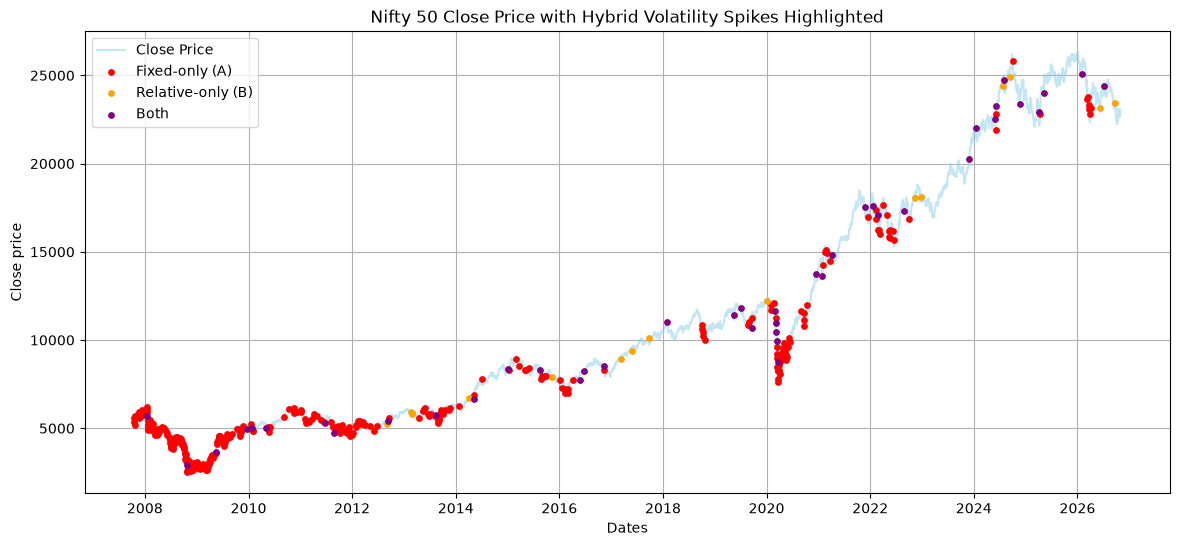

In [108]:
plt.figure(figsize=(14,6))
plt.plot(df_model["Dates"],df_model["Close"],color="skyblue",alpha=0.5, label="Close Price")
colors={
    "Fixed-only (A)":"red",
    "Relative-only (B)":"orange",
    "Both":"purple"
}
for stype,color in colors.items():
    subset=df_model[df_model["Spike_type"]==stype]
    if not subset.empty:
        plt.scatter(subset["Dates"],subset["Close"],color=color,s=15,label=stype,zorder=5)
plt.title("Nifty 50 Close Price with Hybrid Volatility Spikes Highlighted")
plt.xlabel("Dates")
plt.ylabel("Close price")
plt.legend()
plt.grid(True)
plt.show()